<!-- dom:TITLE: 2MA100 - TP final -->
# 2MA100 - TP final
<!-- dom:AUTHOR: Sorbonne Université - 21 mai 2020 -->
<!-- Author: -->  
**Sorbonne Université - 21 mai 2020**

Ce TP final est prévu pour être effectué en **2h**: il n'est pas nécaissaire d'avoir fait les trois exercices pour avoir une note correcte. Les exercices doivent être rendus au choix au format **Notebook** (`.ipynb`) ou **Script** (`.py`) en un ou plusieurs fichiers au plus tard le **21 mai 2020 à 18h** sur [Moodle](https://moodle-sciences.upmc.fr/moodle-2019/). Il ne faut pas indiquer votre prénom, nom ou numéro étudiant dans ce qui est rendu sur Moodle, y compris dans le nom des fichiers afin de garantir votre anonymat lors de la correction. Il n'est pas nécaissaire d'indiquer le numéro d'anonymat de votre convocation d'examen, Moodle se charge d'anonymiser les copies automatiquement.

Il est possible de rendre vos exercices jusqu'à 22h, mais alors le rendu se fait **sous votre propre responsabilité** en cas de défaillance technique (Moodle, ordinateur ou  autre) ne vous permettant pas de rendre vos exercices. En cas de problème technique de 9h à 18h vous pouvez envoyer un email à [julien.guillod@sorbonne-universite.fr](mailto:julien.guillod@sorbonne-universite.fr) en mentionnant `[2MA100 examen]` dans le sujet de votre email.

L'accès aux sites Internet suivants est autorisé:

* Site du cours: <https://python.guillod.org/>

* Carte de référence Python: <https://python.guillod.org/carteref.pdf>

* Documentation de Python: <https://docs.python.org/>

* Documentation de Numpy: <https://docs.scipy.org/>

* Documentation de Matplotlib: <https://matplotlib.org/>

* Documentation de Sympy: <https://docs.sympy.org/>

L'accès à d'autres sites Internet ou ressources (livres, cours, ou autre) ainsi que la communication avec qui que ce soit ne sont pas autorisés. Les tentatives de fraudes seront dénoncées à la section disciplinaire avec les conséquences indiquées dans les [modalités de contrôles des connaissances](https://python.guillod.org/mcc_charte_examens.pdf) (article 8).


Les modules Numpy et Matplotlib peuvent être utiles dans certains exercices:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
sp.init_printing()

<!-- --- begin exercise --- -->

# Exercice 1: Formule de Leibniz

On rappelle la formule de Leibniz:

$$
\dfrac{\pi}{4} = \sum_{k=0}^{\infty} \dfrac{(-1)^k}{2k+1},
$$

et le but est de l'utiliser pour obtenir une approximation de $\pi$.
Pour un entier $n\ge 0$, on note

$$
S_n =  \sum_{k=0}^{n} \dfrac{(-1)^k}{2k+1}.
$$

**a)**
Écrire une fonction qui, à $n$ donné, calcule $S_n$.



In [9]:
def partial(n):
    s = 0
    for k in range(n+1):
        s += (-1)**k/(2*k+1)
    return s
# partial(10)
print(partial(1000) - np.pi/4)

0.00024975018743778055



**b)**
Écrire une fonction dépendant de $\varepsilon$ qui renvoie le plus petit entier $n$
tel que $| \pi - 4 S_n | < \varepsilon$.




**c)**
Tracer l'évolution de $|\pi - 4 S_n |$ en fonction de $n$ pour $3 \le n \le 100$.




**d)**
Vos implémentations des deux questions précédentes sont-elles optimales quand au nombre d'opérations effectuées ?









<!-- --- end exercise --- -->




<!-- --- begin exercise --- -->

# Exercice 2: Equation différentielle

Considérons l'équation différentielle linéaire suivante

$$
\left\{\begin{array}{l}RC\,\dot{u}(t) + u(t)= 0,\\ u(0)=u_0\end{array}\right.
$$

https://femto-physique.fr/omp/runge-kutta.php
https://cahier-de-prepa.fr/PaulConstans/download?id=627

$$\frac{d}{d t} u{\left(t \right)} = - \frac{u{\left(t \right)}}{RC}$$

qui modélise la tension aux bornes d'un condensateur dans un circuit RC (c'est-à-dire composé d'une résistance et d'un condensateur montés en série). Le symbol $RC$ est considéré ici comme une constante, et dans les applications numériques on prendra $RC=0.1$.


**a)**
Ecrire une fonction `sol_exacte(t,u0,RC)` retournant la solution exacte donnée par

\frac{d}{d t} u{\left(t \right)} = - \frac{u{\left(t \right)}}{RC}


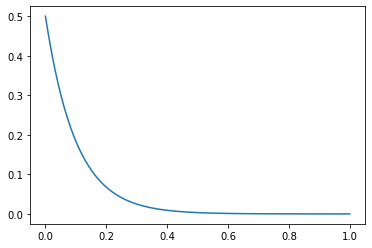

In [70]:
t = sp.Symbol('t')
u = sp.Function('u')
RC = sp.Symbol('RC')
u0 = sp.Symbol(r'u_0')
f = -u(t)/RC
edo = sp.Eq(sp.diff(u(t),t) , f)
print(sp.latex((edo)))
# on peut passer directement les conditions initiales à dsolve() avec icd=
# solgen = sp.dsolve(edo,u(t),ics={u(0):1/2})
solgen = sp.dsolve(edo,u(t))
display(solgen)
consts = sp.solve( sp.Eq( u0, solgen.rhs.subs(t,0)) , dict=True)[0]
display(consts)
solpar = solgen.subs(consts)
solpar = solpar.subs({RC:0.1,u0:1/2})
display(solpar)
func = sp.lambdify(t, solpar.rhs,'numpy')
t = np.linspace(0,1,100)
y = func(t)
display(func(0.2))
plt.plot(t,y)

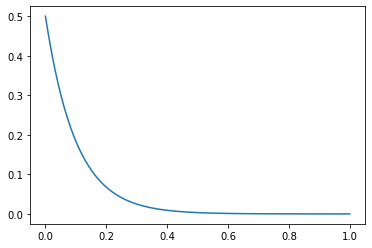

In [59]:
f = sp.Function('f')
x = sp.Symbol('x')
x0 = sp.Symbol(r'x_0')
expr = sp.dsolve(sp.Derivative(f(x),x)*RC + f(x), f(x), ics={f(0):1/2})
display(expr)
# expr = sp.dsolve(sp.Derivative(f(x),x)*RC + f(x), f(x))
expr = expr.subs({RC:0.1})
display(expr)
func = sp.lambdify(x, expr.rhs,'numpy')
t = np.linspace(0,1,100)
y = func(t)
display(func(0.2))
plt.plot(t,y)

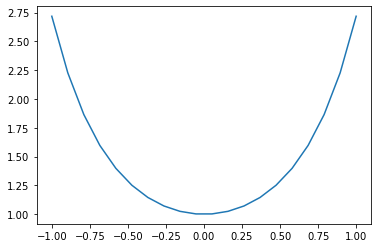

In [75]:
from sympy import *
init_printing

# exemple pris du livre de SGD T1 page 166
y = sp.Function('y')
x = sp.Symbol('x')
f = 2*x*y(x)
edo = Eq(diff(y(x),x),f)
solpar = dsolve(edo, y(x), ics={y(0):1})
# # expr = sp.dsolve(sp.Derivative(f(x),x) - 2*x*f(x), f(x), ics={f(0):1})
# display(expr)
func = sp.lambdify(x, solpar.rhs,'numpy')
t = np.linspace(-1,1,20)
y = func(t)
display(func(0))
plt.plot(t,y)

$$
u(t) = u_0 \exp\left(-\frac{t}{RC}\right).
$$


**b)**
Donner la fonction $f:\mathbb{R}\times \mathbb{R} \to \mathbb{R}$ telle que l'équation différentielle ci-dessus
s'écrit sous la forme canonique $\dot u(t)=f(t,u(t))$ et implémenter cette fonction $f$ en Python.




**c)**
Écrire une fonction permettant de déterminer une solution approchée de l'équation différentielle avec la méthode d'Euler explicite:

$$
u_{n+1} = u_n + \Delta t f(t_n, u_n).
$$

Pour la donnée initiale $u_0=1$ et le temps final $T=1$, comparer graphiquement la courbe obtenue avec la solution exacte, celle obtenue avec la solution approchée pour un pas de temps $\Delta t$ = 0.1 et celle obtenue pour $\Delta t$ = 0.01.




**d)**
Écrire une fonction permettant de déterminer une solution approchée avec une méthode de Runge Kutta d'ordre deux (RK2) donnée par

$$
u_{n+1} = u_{n} + \frac{\Delta t}{2} \bigl[ f(t_n,u_n) + f(t_{n+1},u_*) \bigr]
$$

où

$$
u_* = u_n + \Delta t f(t_n,u_n).
$$


**e)**
Étude qualitative : comparer graphiquement la courbe obtenue avec la solution exacte, celle obtenue avec la solution approchée par RK2 pour $\Delta t$ = 0.1 et celle obtenue pour $\Delta t$ = 0.01, toujours avec $T=1$ et $u_0=1$, puis commenter.




**f)**
Étude quantitative : calculer l'erreur entre la solution exacte et une solution approchée au temps final $T=1$:

$$
E_N=|u(T)−u_N|
$$

pour un pas de temps $\Delta t = T/N$ avec $N$ entier pour les mêmes données initiales que précédemment.
Tracer en échelles logarithmiques la courbe d’erreur en fonction de $\Delta t$ pour les valeurs $N=10,100,1000,10000,100000$ et pour les deux méthodes numériques (Euler explciite et RK2). Comparer ces deux courbes avec les courbes $\sqrt{\Delta t}$, $\Delta t$ et $\Delta t^2$ et commenter.





<!-- --- end exercise --- -->




<!-- --- begin exercise --- -->

# Exercice 3: Interpolation polynomiale

Le but de cet exercice est d'approximer une fonction par un polynôme par la méthode dite des différences divisées.
Pour cela, on considère $n+1$ points distincts $x_0$, $x_1$, ..., $x_n$ et on dispose de $n+1$ valeurs $(y_0,y_1,\dots,y_n)$ de $f$ telles que $y_i = f(x_i)$ pour $i\in\{0,1,\dots,n\}$.
Le but est de déterminer le polynôme $P_n$ tel que $P_n(x_i)=y_i$, *i.e.* le polynôme d'interpolation de Lagrange.
Pour ce faire, on introduit les différences divisées définies par:

$$
[\![y_i]\!] = y_i \,, \quad \forall i\in\{0,1,\dots,n\} \,,
$$

puis à l'ordre 1 par:

$$
[\![y_i,y_{i+1}]\!] = \dfrac{[\![y_{i+1}]\!] - [\![y_i]\!] }{x_{i+1} - x_i} \,,  \quad \forall i\in\{0,\dots,n-1\} \,,
$$

puis à l'ordre 2 par:

$$
[\![y_i,y_{i+1},y_{i+2}]\!] = \dfrac{[\![y_{i+1},y_{i+2}]\!] - [\![y_i,y_{i+1}]\!]}{x_{i+2} - x_i} \,,  \quad \forall i\in\{0,\dots,n-2\} \,,
$$

et ainsi de suite jusqu'à :

$$
[\![y_0,y_1,\ldots,y_{n}]\!] = \dfrac{[\![y_1, y_2,\dots,y_{n}]\!] - [\![y_0,y_1,\dots,y_{n-1}]\!]}{x_{n} - x_0} \,.
$$

Récursivement les différences divisées sont données par:

$$
[\![y_i,\dots,y_{j}]\!] = \dfrac{[\![y_{i+1},\dots,y_{j}]\!] - [\![y_i,\dots,y_{j-1}]\!]}{x_{j}-x_{i}} \,,
$$

pour $0\leq i < j \leq n$.
Le polynôme d’interpolation de Lagrange est alors donné par:

$$
P_n(x) = [\![y_0]\!] + \sum_{i=1}^n [\![y_0,\dots,y_i]\!](x-x_0)(x-x_1) \cdots (x-x_{i-1})
$$

Pour programmer cet algorithme, on remplit un tableau triangulaire à double entrée: à chaque étape on remplit une colonne supplémentaire.

$$
\begin{array}{c|c|c|c|c|c}
\mbox{étape} & t=0 & t=1& t=2&\cdots &t=n \\ 
\hline
\mbox{tableau[0]} & [\![y_0]\!] & & & & \\ 
\mbox{tableau[1]} & [\![y_1]\!] & [\![y_0,y_1]\!] & & & \\ 
\mbox{tableau[2]} & [\![y_2]\!] & [\![y_1,y_2]\!] & [\![y_0,y_1,y_2]\!] & & \\ 
\vdots  & \vdots & \vdots & \vdots & \vdots \\ 
\mbox{tableau[n]} & [\![y_n]\!] & [\![y_{n-1},y_{n}]\!] & [\![y_{n-2},y_{n-1},y_{n}]\!] & &  [\![y_0,\dots,y_{n}]\!]
\end{array}
$$

**a)**
Écrire une fonction `differences(x_interp,y_interp)` qui prend en argument les listes ou vecteurs $(x_0,\dots,x_n)$ et $(y_0,\dots,y_n)$ et qui retournent la liste ou le vecteur des différences divisées $([\![y_0]\!],\dots,[\![y_0,\cdots,y_n]\!])$.




**b)**
Écrire une fonction `interpole(a,x_interp,liste)` qui calcule la valeur de $P_n$ en un point $a\in\mathbb{R}$ où `x_interp` représente $(x_0,\dots,x_n)$ et `liste` est la sortie de la fontion `differences`.




**c)**
On considère la fonction $f(x)=1/(1+10 x^2)$. Construire l'approximation polynomiale $P_n$ de $f$ par interpolation en cinq points régulièrement repartis dans l'intervalle $[0,1]$. Tracer sur la même figure, les graphes de la fonction $f$ et du polynôme $P_n$ en prenant 50 points pour la discrétisation des fonctions.



In [ ]:
https://femto-physique.fr/omp/runge-kutta.php
https://www.physagreg.fr/mecanique-12-chute-frottements.php#:~:text=Alors%20la%20force%20de%20frottements,%3D%E2%88%92kv%E2%86%92v.

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30] [0, 9.75, 19.12, 27.79, 35.54, 42.26, 47.92, 52.58, 56.35, 59.35, 61.71, 63.55, 64.97, 66.06, 66.89, 67.53, 68.01, 68.38, 68.66, 68.87, 69.03, 69.15, 69.24, 69.31, 69.36, 69.4, 69.43, 69.45, 69.46, 69.48, 69.49]


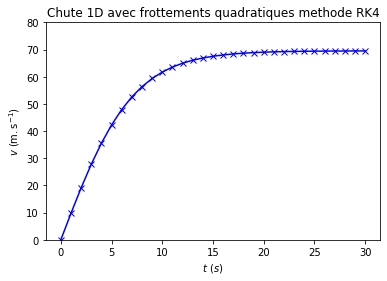

In [1]:
import numpy, math, matplotlib
from pylab import *
t, dt, tmax = 0 , 1 , 30  #initialisation du temps
x = [0] #creation liste des temps
y0 = 0 #condition initiale de vitesse
y=[0]   #creation liste des vitesses

while t < tmax: #tant que t est inferieur a tmax
    t = t + dt #on incremente le temps
    x.append(round(t,2)) # on rentre ce temps dans la liste
    #calcul des coefficients RK4
    k1 = (-0.00203*y0**2+9.81)*dt  
    k2 = (-0.00203*(y0+0.5*k1)**2+9.81)*dt
    k3 = (-0.00203*(y0+0.5*k2)**2+9.81)*dt
    k4 = (-0.00203*(y0+k3)**2+9.81)*dt
    # calcul de la vitesse a n+1
    y1 = y0 + (1/6.0)*(k1 + 2*k2 + 2*k3 + k4)*dt
    y0 = y1 # on remplace la valeur de la vitesse a n par celle a n+1
    y.append(round(y1,2)) #on rentre la vitesse dans la liste 
    
print (x,y) #on affiche les valeurs de temps et de vitesse dans la console
 
plt.plot(x,y,"b-x") #b pour bleu ; - pour ligne continue ; x pour les marqueurs en croix
plt.ylabel('$v$ ($\mathrm{m.s^{-1}}$)') #legende de l axe des y
plt.ylim(ymin = 0, ymax = 80) # on peut fixer les limites des axes
plt.xlabel("$t$ ($s$)") #legende de l axe des x
plt.title("Chute 1D avec frottements quadratiques methode RK4") # titre du graphique
plt.show() # on montre le graphique

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30] [0, 9.8, 19.41, 28.44, 36.6, 43.68, 49.61, 54.41, 58.2, 61.12, 63.34, 65.0, 66.22, 67.12, 67.77, 68.25, 68.59, 68.84, 69.02, 69.15, 69.24, 69.31, 69.36, 69.39, 69.42, 69.44, 69.45, 69.46, 69.46, 69.47, 69.47]


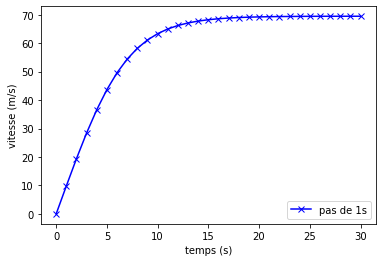

In [1]:
# -*- coding: utf8 -*-                        #le fichier est encodÃ© en utf8
import numpy, math, matplotlib                #Importations de librairies utiles (calculs, fonctions, graphiques)
from pylab import *                           #Utilisation des librairies prÃ©cÃ©dentes

t, dt, tmax = 0 , 1, 30                      #initialisation des paramÃ¨tres de temps                                
x = [0]                                       #initialisation d'une liste avec les dates
y0 = 0                                    #initialisation de la vitesse  
y=[0]                                       #initialisation d'une liste avec les vitesses
fichier=open("euler-chute.txt",'w')           #ouverture du fichier pour stocker liste de points
while t < tmax:                               #Tant que la date est infÃ©rieure Ã  la date max
   t = t + dt                                 #on incrÃ©mente la date avec le pas de calcul
   x.append(round(t,2))                       #on ajoute cette nouvelle date Ã  la fin de la liste des dates (round                                                                                      permet l'affichage de  deux dÃ©cimales)
   y1 = y0 + (-0.00203*y0*y0+9.8)*dt          #on calcule la vitesse Ã  l'instant n+1
   y0 = y1                                     #on affecte Ã  l'ancienne vitesse la nouvelle pour la boucle suivante
   y.append(round(y1,2))                      #on ajoute la nouvelle vitesse Ã  la fin de la liste des vitesses
   fichier.write(str(round(t,2))+"\t"+str(round(y1,2))+"\n") #on Ã©crit la date et la vitesse Ã  l'instant n+1 dans                                                                                                       le fichier
fichier.close()                               #on ferme le fichier de stockage
    
print (x,y)                                   #on affiche les valeurs de temps et de vitesses calculÃ©es
  
plt.plot(x,y,"b-x", label="pas de 1s")        #b pour bleu ; - pour ligne continue ; x pour les marqueurs en croix
plt.xlabel("temps (s)")                       #nom de l'axe des abscisses
plt.ylabel("vitesse (m/s)")                   #nom de l'axe des abscisses
plt.legend(loc='lower right')
plt.show()                                    #on montre le graphique


<!-- --- end exercise --- -->